# Machine Learning Mini Project — Phase 2

## Movie Recommendation System Using Machine Learning
### A Historical Hotstar Catalogue Study

### **Student 1:** Adithya Nayak — **Register number:** 251090700070

### **Student 2:** Shrinidhi Acharya — **Register number:** 251090700077


## 1. Introduction, Problem Statement and Objectives

Users may find it difficult to choose a movie from a large catalogue. This project recommends unseen movies using movie content and user preferences.

**Problem:** Given a user's previous ratings or selected favourites, rank suitable movies. There is no single correct movie for every user.

**Objectives:**
1. Explore and preprocess the same Hotstar and MovieLens datasets used in Phase 1.
2. Implement six supervised models, including bagging and boosting ensembles.
3. Implement recommendation-specific approaches for comparison.
4. Select a model using validation NDCG@10, then report untouched-test performance.
5. Produce top-10 recommendations and explain the scope and limitations of the result.

This is a recommendation/ranking task. The supervised models predict a **0.5–5 rating** and use that prediction to rank movies. Movie genres are features, not the prediction target.

## 2. Dataset Description and Sources

| File | Meaning | Role |
|---|---|---|
| `data/hotstar.csv` | Historical movies and TV shows with titles, descriptions, genres, years and runtimes | Movie content and catalogue |
| `data/ml-latest-small/movies.csv` | MovieLens movie IDs, titles and genres | Candidate title/year linkage |
| `data/ml-latest-small/ratings.csv` | User ID, movie ID, rating and timestamp | Real observed user preferences |

Use only movies from Hotstar. The datasets do not share IDs, so join unambiguous normalized titles and exact release years. Export the candidates for review; this is not an authoritative identity mapping. The smaller matched subset supports quantitative model comparisons. The full movie catalogue supports a separate content-only demonstration.

Sources: [Hotstar repository](https://github.com/SumitMakariye/Hotstar-Data-Analysis-Using-Python), [MovieLens](https://grouplens.org/datasets/movielens/latest/). The original MovieLens README and Hotstar source-repository licence are included. The original Hotstar collection date, territory and current availability are unverified.

## 3. Libraries and Data Preparation

NumPy and pandas support data processing; Matplotlib provides visualizations; SciPy and scikit-learn support feature engineering, model training and evaluation. The datasets are loaded and movie records are prepared for analysis.


In [1]:
import importlib.util
import subprocess
import sys
packages = {'numpy':'numpy>=1.24,<3', 'pandas':'pandas>=2,<3',
            'scipy':'scipy>=1.10,<2', 'sklearn':'scikit-learn>=1.3,<2',
            'matplotlib':'matplotlib>=3.7,<4', 'IPython':'ipython>=8',
            'threadpoolctl':'threadpoolctl>=3'}
missing = [spec for name,spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Libraries ready.')

from pathlib import Path
import html
import re, unicodedata, json, hashlib, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display, Markdown

SEED = 42
K = 10
RELEVANT_RATING = 4.0
# Optionally set this to the extracted project folder on another computer.
PROJECT_DIR = None  # Example: Path(r'C:/path/to/Movie_Recommendation_Phase2')
if PROJECT_DIR is not None:
    roots = [Path(PROJECT_DIR).expanduser()]
else:
    roots = [Path.cwd(), Path.cwd() / 'Movie_Recommendation_Phase3',
             Path.cwd().parent]
PROJECT_ROOT = next((root.resolve() for root in roots
                     if (root / 'data' / 'SHA256.json').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cannot locate the Phase 2 data folder. Extract the complete project ZIP, '
        'set PROJECT_DIR above to the folder containing data, and run this setup cell again. '
        'The notebook alone does not contain the CSV datasets.')
DATA = PROJECT_ROOT / 'data'
OUT = PROJECT_ROOT / 'evaluation'
print('Dataset folder:', DATA)
OUT.mkdir(exist_ok=True)
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)
def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()
versions = {'python': platform.python_version(), 'numpy':np.__version__,
            'pandas':pd.__version__, 'scipy':scipy.__version__, 'sklearn':sklearn.__version__}
print(versions)

manifest_file = DATA / 'SHA256.json'
if not manifest_file.exists():
    raise FileNotFoundError('Extract the complete Phase 2 ZIP and open the notebook inside its folder.')
manifest = json.loads(manifest_file.read_text())
for name, expected in manifest.items():
    path = DATA / name
    if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f'Dataset integrity check failed: {name}. Re-extract the supplied ZIP.')
raw = pd.read_csv(DATA / 'hotstar.csv', dtype={'hotstar_id':str})
ml_movies = pd.read_csv(DATA / 'ml-latest-small/movies.csv')
ratings = pd.read_csv(DATA / 'ml-latest-small/ratings.csv')
assert len(ratings) == 100836 and ratings.userId.nunique() == 610

movies = raw.loc[raw['type'].astype(str).str.lower().eq('movie')].copy()
movies = movies.dropna(subset=['hotstar_id','title'])
for col in ['title','description','genre','age_rating']:
    movies[col] = movies[col].fillna('').astype(str).str.strip()
# Decode HTML entities in catalogue titles before cleaning and matching.
movies['title'] = movies['title'].map(html.unescape)
movies = movies.loc[movies.title.ne('')].drop_duplicates('hotstar_id').copy()
movies['_t'] = movies.title.str.lower()
movies = (movies.sort_values('hotstar_id')
                .drop_duplicates(['_t', 'year', 'description'])
                .drop(columns='_t').reset_index(drop=True))
print('Movies after removing duplicate listings:', len(movies))
assert len(movies) == 4557, 'Unexpected catalogue snapshot after deduplication.'
movies['genre'] = movies.genre.replace('', 'Unknown')
for col in ['year','running_time']:
    movies[col] = pd.to_numeric(movies[col],errors='coerce')
movies.loc[movies.running_time.le(0),'running_time'] = np.nan
movies['description_words'] = movies.description.str.split().str.len()

print(f'Setup complete: {len(movies):,} movies and {len(ratings):,} ratings loaded.')


Libraries ready.


Dataset folder: D:\3MIT\ML PROJECT\Movie_Recommendation_Phase3\data
{'python': '3.12.14', 'numpy': '2.5.4', 'pandas': '2.3.3', 'scipy': '1.18.1', 'sklearn': '1.9.1'}
Movies after removing duplicate listings: 4557
Setup complete: 4,557 movies and 100,836 ratings loaded.


**Library versions used in the analysis.**


In [2]:
print('Loaded library versions:')
print(versions)


Loaded library versions:
{'python': '3.12.14', 'numpy': '2.5.4', 'pandas': '2.3.3', 'scipy': '1.18.1', 'sklearn': '1.9.1'}


## 4. Reading Data and Checking Integrity

SHA-256 checksums verify the dataset snapshot. Row counts, column types, missing values and duplicate records describe the loaded tables.


In [3]:
for name, df in [('Hotstar',raw),('MovieLens movies',ml_movies),('MovieLens ratings',ratings)]:
    print(f'\n{name}: {df.shape[0]:,} rows, {df.shape[1]} columns')
    display(df.head(3))
    display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(), 'unique':df.nunique()}))
    print('Duplicate full rows:', df.duplicated().sum())
print('Duplicate user/movie pairs:',ratings.duplicated(['userId','movieId']).sum())
assert ratings[['userId','movieId','rating']].notna().all().all()
assert ratings.rating.between(0.5,5).all()
assert not ratings.duplicated(['userId','movieId']).any()
assert ratings.movieId.isin(ml_movies.movieId).all()


Hotstar: 6,874 rows, 10 columns


,hotstar_id,title,description,genre,year,age_rating,running_time,seasons,episodes,type
0,1000087439,Sambha - Aajcha Chawa,A young man sets off on a mission to clean up the society from corruption an...,Action,2012,U/A 16+,141.0,NaN,NaN,movie
1,1260023113,Cars Toon: Mater And The Ghostlight,Mater is haunted by a mysterious blue light that teaches him not to play pra...,Animation,2006,U,7.0,NaN,NaN,movie
2,1260103188,Kanmani Rambo Khatija,"Unlucky since birth, Rambo finds hope when he falls in love with Kanmani and...",Romance,2022,U/A 16+,157.0,NaN,NaN,movie


,dtype,missing,unique
hotstar_id,object,0,6874
title,object,0,6677
description,object,0,6815
genre,object,0,37
year,int64,0,78
age_rating,object,0,6
running_time,float64,2306,187
seasons,float64,4568,40
episodes,float64,4568,495
type,object,0,2


Duplicate full rows: 0

MovieLens movies: 9,742 rows, 3 columns


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,dtype,missing,unique
movieId,int64,0,9742
title,object,0,9737
genres,object,0,951


Duplicate full rows: 0

MovieLens ratings: 100,836 rows, 4 columns


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224


,dtype,missing,unique
userId,int64,0,610
movieId,int64,0,9724
rating,float64,0,10
timestamp,int64,0,85043


Duplicate full rows: 0
Duplicate user/movie pairs: 0


## 5. Data Preprocessing

**Preparing movie records.** Keep unique valid movie IDs and nonempty titles. Missing descriptions become empty text; missing genres become `Unknown`. Non-positive runtimes become missing. TV-specific `seasons` and `episodes` are not movie features. Identifiers are keys, not continuous numeric predictors.

In [4]:
print('Movie records retained:',len(movies))
print('Empty descriptions:',movies.description.eq('').sum())
display(movies[['year','running_time','description_words']].describe().T)
print('Missing seasons/episodes in movie rows are structural, not errors.')

Movie records retained: 4557
Empty descriptions: 0


,count,mean,std,min,25%,50%,75%,max
year,4557.0,2008.691244,13.269101,1928.0,2005.0,2012.0,2018.0,2023.0
running_time,4557.0,98.624314,49.397349,1.0,70.0,116.0,135.0,229.0
description_words,4557.0,25.011630,5.232991,9.0,23.0,25.0,27.0,114.0


Missing seasons/episodes in movie rows are structural, not errors.


## 6. Exploratory Data Analysis

**Plotting genres, catalogue age ratings, years and running times.** These charts describe the supplied catalogue. No preference labels or test results determine modelling choices here.

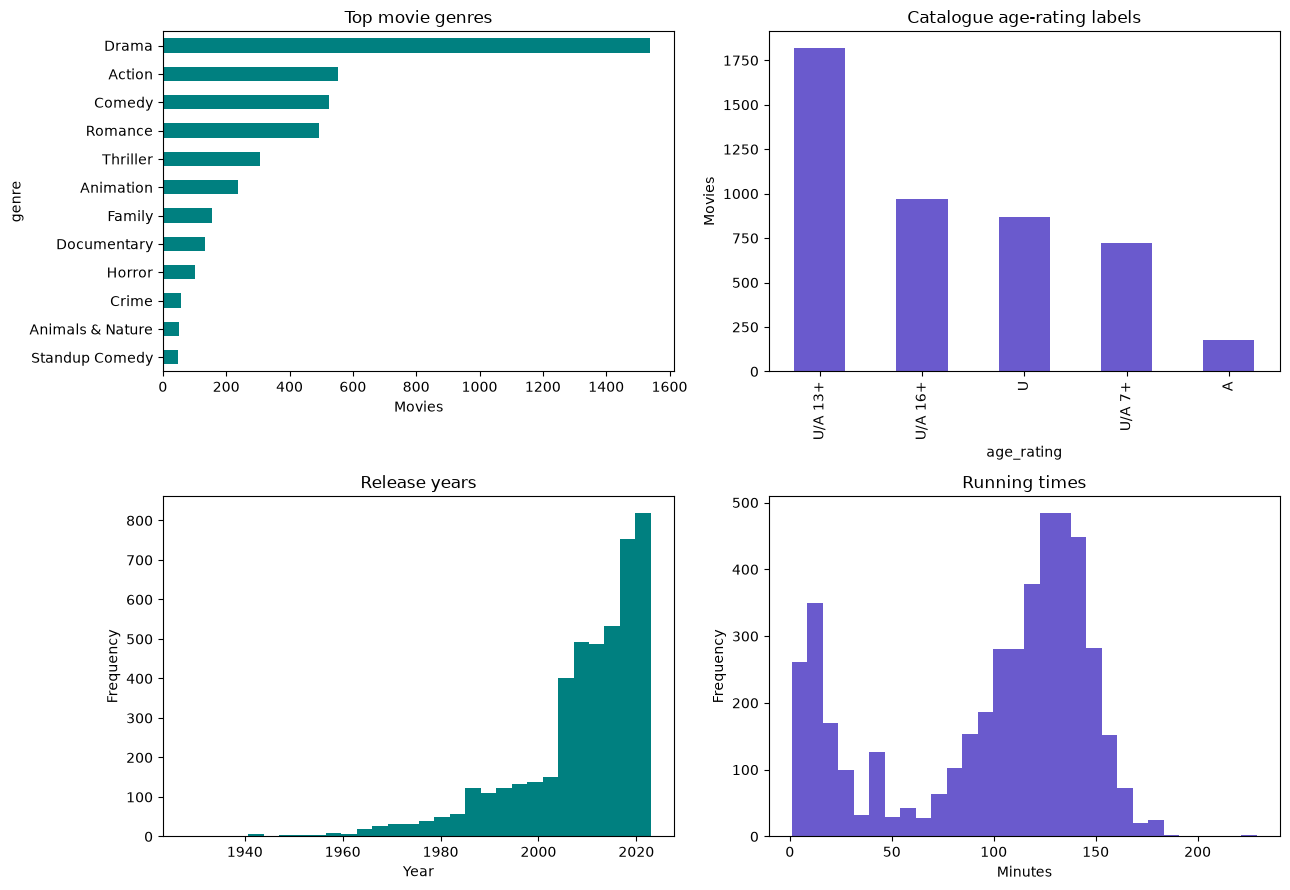

,feature,lower,upper,flagged
0,year,1985.5,2037.5,326
1,running_time,-27.5,232.5,0
2,description_words,17.0,33.0,233


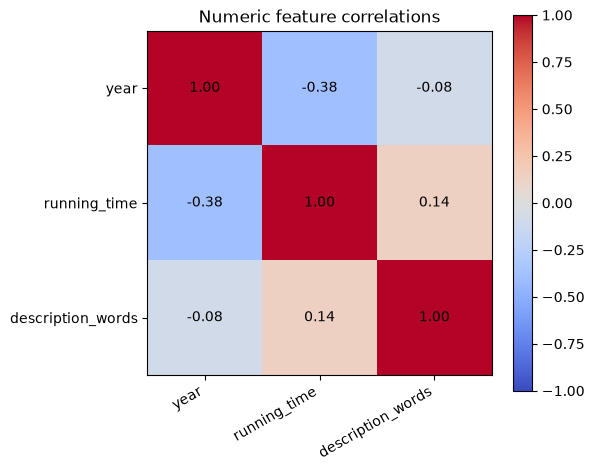

IQR flags are inspected, not automatically removed: short films and old movies can be valid.


In [5]:
fig, axes = plt.subplots(2,2,figsize=(13,9))
movies.genre.value_counts().head(12).sort_values().plot.barh(ax=axes[0,0],color='teal')
axes[0,0].set(title='Top movie genres',xlabel='Movies')
movies.age_rating.replace('','Unknown').value_counts().plot.bar(ax=axes[0,1],color='slateblue')
axes[0,1].set(title='Catalogue age-rating labels',ylabel='Movies')
movies.year.dropna().plot.hist(bins=30,ax=axes[1,0],color='teal')
axes[1,0].set(title='Release years',xlabel='Year')
movies.running_time.dropna().plot.hist(bins=30,ax=axes[1,1],color='slateblue')
axes[1,1].set(title='Running times',xlabel='Minutes')
show_plot('01_catalogue_eda')

cols=['year','running_time','description_words']
outliers=[]
for col in cols:
    q1,q3=movies[col].quantile([0.25,0.75]);spread=q3-q1
    outliers.append({'feature':col,'lower':q1-1.5*spread,'upper':q3+1.5*spread,
                     'flagged':int(((movies[col]<q1-1.5*spread)|(movies[col]>q3+1.5*spread)).sum())})
display(pd.DataFrame(outliers))
corr=movies[cols].corr()
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(3),cols,rotation=30,ha='right');ax.set_yticks(range(3),cols)
for i in range(3):
    for j in range(3):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax);ax.set_title('Numeric feature correlations')
show_plot('02_correlations')
print('IQR flags are inspected, not automatically removed: short films and old movies can be valid.')

**Studying ratings and sparsity.** A missing rating means unknown preference, not dislike. This full-data EDA is descriptive; training, feature construction and model selection below respect the split.

MovieLens user/catalogue matrix is 98.30% unobserved.


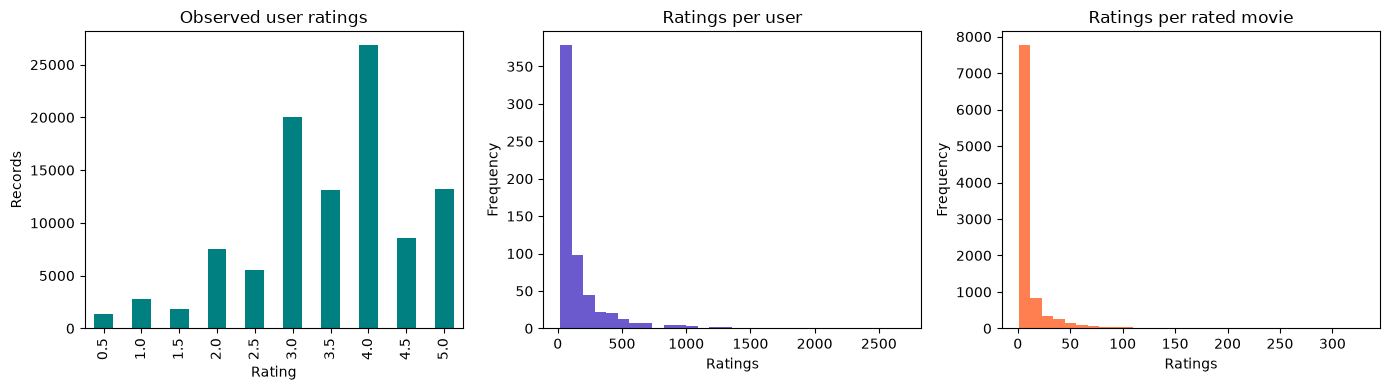

In [6]:
sparsity=1-len(ratings)/(ratings.userId.nunique()*len(ml_movies))
print(f'MovieLens user/catalogue matrix is {sparsity:.2%} unobserved.')
fig,axes=plt.subplots(1,3,figsize=(14,4))
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0],color='teal')
axes[0].set(title='Observed user ratings',xlabel='Rating',ylabel='Records')
ratings.groupby('userId').size().plot.hist(bins=30,ax=axes[1],color='slateblue')
axes[1].set(title='Ratings per user',xlabel='Ratings')
ratings.groupby('movieId').size().plot.hist(bins=30,ax=axes[2],color='coral')
axes[2].set(title='Ratings per rated movie',xlabel='Ratings')
show_plot('03_ratings_eda')

## 7. Linking the Datasets

**Matching normalized title and exact release year.** Exclude missing years and ambiguous keys on either side. The exported CSV allows manual review. Alternate titles/transliterations can be missed; apparent matches can still be wrong. All reported ranking results apply to the linked subset, not the full catalogue.

Matched movies: 304 of 4557 (6.67%)
Matched ratings: 8125 | Users: 572


,title,title_movielens,year
0,Dragon Blade,Dragon Blade (2015),2015
1,Spider-Man,Spider-Man (2002),2002
2,John Carter,John Carter (2012),2012
3,Captain America: The Winter Soldier,Captain America: The Winter Soldier (2014),2014
4,Shanghai Knights,Shanghai Knights (2003),2003
5,Finding Dory,Finding Dory (2016),2016
6,Captain America: Civil War,Captain America: Civil War (2016),2016
7,Cars 2,Cars 2 (2011),2011
8,Alice In Wonderland,Alice in Wonderland (2010),2010
9,Race To Witch Mountain,Race to Witch Mountain (2009),2009


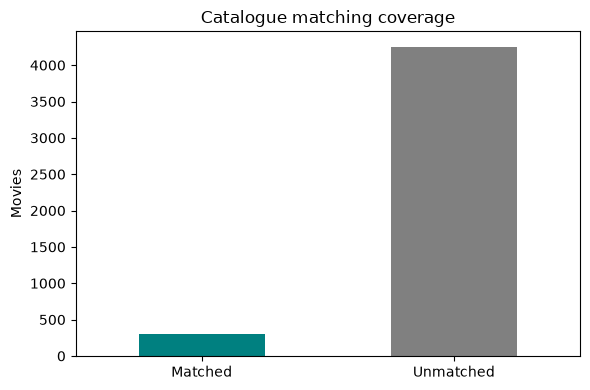

In [7]:
def title_key(title):
    title=re.sub(r'\s*\(\d{4}\)\s*$','',str(title))
    title=unicodedata.normalize('NFKD',title).encode('ascii','ignore').decode().lower()
    title=re.sub(r',\s*(the|a|an)$',r' \1',title)
    return re.sub(r'[^a-z0-9]','',title)
movies['title_key']=movies.title.map(title_key)
ml_movies['title_key']=ml_movies.title.map(title_key)
ml_movies['year']=pd.to_numeric(ml_movies.title.str.extract(r'\((\d{4})\)$')[0],errors='coerce')
left=movies.loc[movies.year.notna() & movies.title_key.ne('')].copy()
right=ml_movies.loc[ml_movies.year.notna() & ml_movies.title_key.ne('')].copy()
left=left.loc[~left.duplicated(['title_key','year'],keep=False)]
right=right.loc[~right.duplicated(['title_key','year'],keep=False)]
matched=left.merge(right[['movieId','title','title_key','year']],on=['title_key','year'],
                   suffixes=('','_movielens'),validate='one_to_one').sort_values('hotstar_id').reset_index(drop=True)
matched['item_idx']=np.arange(len(matched))
interactions=ratings.merge(matched[['movieId','hotstar_id','item_idx']],on='movieId',validate='many_to_one')
interactions=interactions.sort_values(['userId','movieId']).reset_index(drop=True)
matched[['hotstar_id','title','movieId','title_movielens','year']].to_csv(OUT/'title_matches_for_review.csv',index=False)
print('Matched movies:',len(matched),'of',len(movies),f'({len(matched)/len(movies):.2%})')
print('Matched ratings:',len(interactions),'| Users:',interactions.userId.nunique())
display(matched[['title','title_movielens','year']].head(10))
assert matched.hotstar_id.is_unique and matched.movieId.is_unique
assert len(matched)==304 and len(interactions)==8125
fig,ax=plt.subplots(figsize=(6,4))
pd.Series({'Matched':len(matched),'Unmatched':len(movies)-len(matched)}).plot.bar(ax=ax,color=['teal','gray'])
ax.set(title='Catalogue matching coverage',ylabel='Movies');plt.xticks(rotation=0)
show_plot('04_matching_coverage')

## 8. Train, Validation and Test Split

**Creating one fixed per-user split.** For users with at least five matched ratings, reserve `floor(20%)` for validation and `floor(20%)` for test, and use the rest for training. Users with fewer than five ratings contribute training data only. Actual proportions differ from 60/20/20 because of rounding and sparse users.

Choose the winner using validation NDCG@10 (Recall@10 breaks ties). Refit using train + validation, then evaluate on test once. Test results do not change the selected winner. This random holdout evaluates known users and is not a chronological/future prediction test.

In [8]:
rng=np.random.default_rng(SEED)
val_idx=[];test_idx=[]
for user,g in interactions.groupby('userId',sort=True):
    if len(g)>=5:
        order=rng.permutation(g.index.to_numpy());n=max(1,int(len(g)*0.2))
        val_idx.extend(order[:n]);test_idx.extend(order[n:2*n])
train=interactions.drop(index=val_idx+test_idx).copy()
validation=interactions.loc[val_idx].copy()
test=interactions.loc[test_idx].copy()
assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
assert len(train)+len(validation)+len(test)==len(interactions)
assert set(validation.userId).issubset(set(train.userId))
assert set(test.userId).issubset(set(train.userId))
split_summary=pd.DataFrame({'Split':['Train','Validation','Test'],
                           'Ratings':[len(train),len(validation),len(test)]})
split_summary['Percent']=100*split_summary.Ratings/len(interactions)
display(split_summary)
for name,df in [('train',train),('validation',validation),('test',test)]:
    df[['userId','movieId','rating','timestamp']].to_csv(OUT/(name+'_ratings.csv'),index=False)

,Split,Ratings,Percent
0,Train,5327,65.563077
1,Validation,1399,17.218462
2,Test,1399,17.218462


## 9. Content Feature Engineering

**Converting descriptions and genres into TF-IDF vectors.** A 20-component Truncated SVD creates compact movie vectors for the supervised models. Public catalogue metadata is treated as known in advance (a transductive catalogue setting). No user ratings enter these transforms. The interaction-based SVD recommender later is a separate model.

In [9]:
vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=12000,sublinear_tf=True)
text=(matched.description.fillna('')+' '+matched.genre.fillna('')+' '+matched.genre.fillna(''))
T=vectorizer.fit_transform(text)
content_svd=TruncatedSVD(n_components=min(20,T.shape[0]-1,T.shape[1]-1),random_state=SEED)
E=normalize(content_svd.fit_transform(T)).astype(np.float64)
M=len(matched)
U=int(interactions.userId.max())+1  # IDs are indexing keys, never magnitude features.
print('TF-IDF shape:',T.shape,'| Compact content shape:',E.shape)
print('Variance captured:',round(float(content_svd.explained_variance_ratio_.sum()),3))

TF-IDF shape: (304, 6502) | Compact content shape: (304, 20)
Variance captured: 0.115


## 10. Leakage-Safe User–Movie Features

**Building user profiles and rating statistics from reference interactions only.** Features include the movie vector, the user's positive-preference vector, their elementwise product, similarity, user mean/count and smoothed movie mean/count. No raw user or movie ID is used as a numeric predictor.

For supervised training rows, build these features using five-fold **out-of-fold reference histories**: the fold containing the target rating is excluded. This prevents a training target from appearing in its own user profile or movie-average feature. These folds are for feature construction, not hyperparameter selection. Validation/test features use training/refit history only. Out-of-fold histories are smaller than final histories, a remaining distribution difference.

In [10]:
def make_state(reference):
    user=reference.userId.to_numpy(dtype=int)
    item=reference.item_idx.to_numpy(dtype=int)
    y=reference.rating.to_numpy(float)
    uc=np.bincount(user,minlength=U).astype(float)
    us=np.bincount(user,weights=y,minlength=U)
    ic=np.bincount(item,minlength=M).astype(float)
    isum=np.bincount(item,weights=y,minlength=M)
    mu=float(y.mean())
    pos=np.maximum(y-3.0,0.0)
    A=csr_matrix((pos,(user,item)),shape=(U,M))
    observed=csr_matrix((np.ones(len(y)),(user,item)),shape=(U,M))
    weights=np.asarray(A.sum(axis=1)).ravel()
    profile=np.asarray(A@E)/np.maximum(weights[:,None],1e-12)
    profile=normalize(profile)
    um=np.divide(us,uc,out=np.full(U,mu),where=uc>0)
    im=(isum+10*mu)/(ic+10)
    return dict(A=A,observed=observed,profile=profile,uc=uc,um=um,ic=ic,im=im,mu=mu)

def pair_features(state,users,items):
    users=np.asarray(users,dtype=int);items=np.asarray(items,dtype=int)
    p=state['profile'][users];e=E[items]
    return np.column_stack([e,p,e*p,np.sum(e*p,axis=1),state['um'][users],
                            np.log1p(state['uc'][users]),state['im'][items],
                            np.log1p(state['ic'][items])])

feature_names=([f'movie_content_{i}' for i in range(E.shape[1])]+
               [f'user_profile_{i}' for i in range(E.shape[1])]+
               [f'content_product_{i}' for i in range(E.shape[1])]+
               ['profile_similarity','user_mean_rating','log_user_count',
                'smoothed_movie_mean','log_movie_count'])

def training_features(reference):
    reference=reference.reset_index(drop=True)
    X=np.empty((len(reference),len(feature_names)))
    folds=KFold(n_splits=5,shuffle=True,random_state=SEED)
    for reference_pos,target_pos in folds.split(reference):
        assert not set(reference_pos).intersection(target_pos)
        state=make_state(reference.iloc[reference_pos])
        held=reference.iloc[target_pos]
        X[target_pos]=pair_features(state,held.userId,held.item_idx)
    assert np.isfinite(X).all()
    return X,reference.rating.to_numpy(float)

train_state=make_state(train)
X_train,y_train=training_features(train)
print('Supervised training feature matrix:',X_train.shape)
print('Targets are observed ratings, not generated labels.')

Supervised training feature matrix: (5327, 65)
Targets are observed ratings, not generated labels.


## 11. Implementing Six Supervised Models

All six receive the **same rows and out-of-fold features**. Scaling is fitted only on training features for Ridge, KNN and SVR. Tree models do not require scaling. Hyperparameters below are fixed in advance; no test tuning or exhaustive search is claimed.

| Model | Type | Settings |
|---|---|---|
| Ridge Regression | Linear | alpha = 10 |
| KNN Regressor | Neighbour model | 25 neighbours, distance weighting |
| Decision Tree Regressor | Single tree | max depth 8, min leaf size 15 |
| SVR | Kernel model | RBF, C = 3, epsilon = 0.2 |
| Random Forest Regressor | **Ensemble: bagging/randomized trees** | 120 trees, max depth 12, min leaf 5 |
| Gradient Boosting Regressor | **Ensemble: boosting** | 120 stages, learning rate 0.05, depth 2 |

Predictions are clipped to the valid rating range 0.5–5.

In [11]:
def model_definitions():
    return {
        'Ridge':make_pipeline(StandardScaler(),Ridge(alpha=10)),
        'KNN':make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=25,weights='distance',n_jobs=1)),
        'Decision Tree':DecisionTreeRegressor(max_depth=8,min_samples_leaf=15,random_state=SEED),
        'SVR':make_pipeline(StandardScaler(),SVR(C=3,epsilon=0.2,kernel='rbf')),
        'Random Forest':RandomForestRegressor(n_estimators=120,max_depth=12,min_samples_leaf=5,
                                              max_features=0.8,n_jobs=1,random_state=SEED),
        'Gradient Boosting':GradientBoostingRegressor(n_estimators=120,learning_rate=0.05,
                                                     max_depth=2,min_samples_leaf=10,random_state=SEED)
    }

def fit_supervised(reference):
    start=time.perf_counter();X,y=training_features(reference)
    preprocessing_time=time.perf_counter()-start
    models=model_definitions();times={}
    for name,model in models.items():
        start=time.perf_counter();model.fit(X,y)
        times[name]=time.perf_counter()-start
        print(f'{name}: fitted on {len(y):,} ratings in {times[name]:.2f}s',flush=True)
    return models,times,preprocessing_time

models,fit_times,feature_seconds=fit_supervised(train)
assert len(models)==6
print('Shared out-of-fold feature generation seconds:',round(feature_seconds,2))

Ridge: fitted on 5,327 ratings in 0.01s


KNN: fitted on 5,327 ratings in 0.01s


Decision Tree: fitted on 5,327 ratings in 0.15s


SVR: fitted on 5,327 ratings in 1.64s


Random Forest: fitted on 5,327 ratings in 11.09s


Gradient Boosting: fitted on 5,327 ratings in 4.65s


Shared out-of-fold feature generation seconds: 0.01


## 12. Recommendation-Specific Models and Baseline

Five additional approaches provide useful comparisons:

- **Popularity:** Bayesian-smoothed mean rating, discounted for very few observations. No personalization.
- **Content:** Cosine similarity to the user's positive TF-IDF profile (rating above 3).
- **User CF:** Ratings above 3 form positive strengths; use up to 30 similar users, excluding the evaluated user from their own neighbours.
- **Interaction SVD:** A rank-20 approximation of the sparse positive-interaction matrix. Missing cells are zero in this simple baseline; this is not an unbiased explicit-rating matrix-factorization model.
- **Hybrid:** Fixed 0.60 content + 0.35 user-CF + 0.05 popularity, after candidate-wise min–max normalization. Weights are not tuned on test data.

Users with no usable positive history receive popularity fallback for content/CF/SVD. This fallback is part of the defined methods, not an extra trained model.

In [12]:
def recommender_state(reference):
    state=make_state(reference)
    start=time.perf_counter()
    state['user_norm']=normalize(state['A'])
    state['content_profiles']=normalize(state['A']@T)
    state['popularity']=state['im']*state['ic']/(state['ic']+10)
    state['svd']=TruncatedSVD(n_components=min(20,M-1),random_state=SEED)
    state['svd'].fit(state['A'])
    state['svd_seconds']=time.perf_counter()-start
    return state

def minmax(x):
    x=np.asarray(x,float).ravel();spread=np.ptp(x)
    return (x-x.min())/spread if spread>1e-12 else np.zeros_like(x)

def all_scores(user,candidates,state,models):
    candidates=np.asarray(candidates,dtype=int)
    pop=state['popularity'][candidates]
    content=np.asarray((state['content_profiles'][user]@T[candidates].T).toarray()).ravel()
    similarity=np.asarray((state['user_norm']@state['user_norm'][user].T).toarray()).ravel()
    similarity[user]=0
    neighbours=np.argsort(-similarity,kind='stable')[:30]
    neighbours=neighbours[similarity[neighbours]>0]
    cf=np.zeros(len(candidates))
    if len(neighbours):
        w=similarity[neighbours]
        numerator=np.asarray(state['A'][neighbours][:,candidates].T@w).ravel()
        denominator=np.asarray(state['observed'][neighbours][:,candidates].T@w).ravel()
        cf=np.divide(numerator,denominator,out=np.zeros_like(numerator),where=denominator>0)
    latent=state['svd'].transform(state['A'][user])
    svd=(latent@state['svd'].components_[:,candidates]).ravel()
    if not np.any(content):content=pop.copy()
    if not np.any(cf):cf=pop.copy()
    if not np.any(svd):svd=pop.copy()
    scores={'Popularity':pop,'Content':content,'User CF':cf,'Interaction SVD':svd,
            'Hybrid':0.6*minmax(content)+0.35*minmax(cf)+0.05*minmax(pop)}
    X=pair_features(state,np.full(len(candidates),user),candidates)
    for name,model in models.items():scores[name]=np.clip(model.predict(X),0.5,5)
    assert all(np.isfinite(x).all() for x in scores.values())
    return scores

state=recommender_state(train)
model_names=list(model_definitions())+['Popularity','Content','User CF','Interaction SVD','Hybrid']
print('Methods compared:',len(model_names))
print('Six supervised models + four recommendation methods + one popularity baseline.')

Methods compared: 11
Six supervised models + four recommendation methods + one popularity baseline.


## 13. Evaluation Protocol and Metrics

**Ranking evaluation:** For each user, rank all matched movies with at least one rating in the reference training history, excluding movies that user already rated there. There is no random negative sampling. Validation and test users are evaluated only if they have at least one relevant held-out movie in this eligible catalogue and at least 10 candidates. All methods share these exact users and candidate sets.

| Metric | Calculation / interpretation |
|---|---|
| Precision@10 | Relevant recommendations / 10 |
| Recall@10 | Relevant recommendations / eligible relevant held-out movies |
| NDCG@10 | Discounted binary relevance, divided by ideal DCG; rewards relevant movies near the top |
| HitRate@10 | Fraction of evaluated users with at least one relevant recommendation |
| Coverage@10 | Distinct recommended movies / reference-observed candidate catalogue size |
| MAE | Mean absolute rating prediction error |
| RMSE | Square root of mean squared rating prediction error |

A held-out rating ≥4 defines relevance. Unobserved candidates count as nonrelevant **for this offline calculation only**; their true preference is unknown. Report excluded users and held-out items outside the reference catalogue. This protocol measures warm-item, known-user performance. Scores are not classification accuracy. Confusion matrices and ROC curves are not the primary evaluation for this ranking problem.

In [13]:
def ranking_metrics(top,relevant,k=K):
    relevance=np.array([int(i in relevant) for i in top[:k]],float)
    hits=relevance.sum()
    discounts=1/np.log2(np.arange(2,k+2))
    dcg=float(np.sum(relevance*discounts[:len(relevance)]))
    ideal=float(discounts[:min(k,len(relevant))].sum())
    return {'Precision@10':hits/k,'Recall@10':hits/len(relevant),
            'NDCG@10':dcg/ideal if ideal else 0.0,'HitRate@10':float(hits>0)}

assert ranking_metrics([1,2,3],{1},k=3)['NDCG@10']==1.0
assert ranking_metrics([2,3,4],{1},k=3)['Recall@10']==0.0

def evaluate_ranking(reference,target,state,models,label):
    eligible=np.flatnonzero(state['ic']>0)
    eligible_set=set(eligible)
    histories={int(u):set(g.item_idx.astype(int)) for u,g in reference.groupby('userId')}
    rows=[];recommended={name:set() for name in model_names};seconds={name:0.0 for name in model_names}
    excluded_no_relevant=0;excluded_candidates=0
    outside=int((~target.item_idx.isin(eligible)).sum())
    start=time.perf_counter()
    for user,g in target.groupby('userId',sort=True):
        user=int(user)
        candidates=np.array([i for i in eligible if i not in histories.get(user,set())],dtype=int)
        relevant=set(g.loc[g.rating>=RELEVANT_RATING,'item_idx'].astype(int))&eligible_set
        if not relevant:
            excluded_no_relevant+=1;continue
        if len(candidates)<K:
            excluded_candidates+=1;continue
        scores=all_scores(user,candidates,state,models)
        for name in model_names:
            order=np.argsort(-scores[name],kind='stable')[:K]
            top=candidates[order]
            assert not set(top).intersection(histories.get(user,set()))
            assert len(np.unique(top))==K
            recommended[name].update(top)
            rows.append(dict(Model=name,userId=user,**ranking_metrics(top,relevant)))
    per_user=pd.DataFrame(rows)
    if per_user.empty:raise ValueError('No eligible users for ranking evaluation.')
    summary=per_user.groupby('Model',sort=False)[['Precision@10','Recall@10','NDCG@10','HitRate@10']].mean()
    summary['Coverage@10']=[len(recommended[n])/len(eligible) for n in summary.index]
    summary['Users']=per_user.groupby('Model').size()
    summary=summary.sort_values(['NDCG@10','Recall@10'],ascending=False,kind='stable')
    audit={'split':label,'target_users':int(target.userId.nunique()),
           'evaluated_users':int(per_user.userId.nunique()),
           'excluded_no_eligible_positive':excluded_no_relevant,
           'excluded_fewer_than_10_candidates':excluded_candidates,
           'reference_observed_movies':len(eligible),
           'target_ratings_outside_reference_catalogue':outside,
           'target_positive_ratings_outside_reference_catalogue':int(((target.rating>=4)&~target.item_idx.isin(eligible)).sum()),
           'evaluation_seconds':round(time.perf_counter()-start,3)}
    summary.to_csv(OUT/(label+'_ranking_metrics.csv'))
    per_user.to_csv(OUT/(label+'_per_user_metrics.csv'),index=False)
    (OUT/(label+'_evaluation_audit.json')).write_text(json.dumps(audit,indent=2))
    return summary,per_user,audit

def evaluate_ratings(reference,target,state,models,label):
    X=pair_features(state,target.userId,target.item_idx)
    X_fit,y_fit=training_features(reference)
    rows=[];predictions={}
    for name,model in models.items():
        pred=np.clip(model.predict(X),0.5,5)
        pred_fit=np.clip(model.predict(X_fit),0.5,5)
        predictions[name]=pred
        rows.append({'Model':name,'MAE':mean_absolute_error(target.rating,pred),
                     'RMSE':np.sqrt(mean_squared_error(target.rating,pred)),
                     'Training RMSE (in-sample)':np.sqrt(mean_squared_error(y_fit,pred_fit)),
                     'Rated pairs':len(target)})
    table=pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
    table.to_csv(OUT/(label+'_rating_metrics.csv'))
    return table,predictions

# Avoid excessive BLAS thread overhead on small matrices; keeps laptop usage predictable.
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
validation_rank,validation_users,validation_audit=evaluate_ranking(train,validation,state,models,'validation')
validation_rating,_=evaluate_ratings(train,validation,state,models,'validation')
display(validation_rank.round(4))
display(validation_rating.round(4))
print('Evaluation scope:',validation_audit)

,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@10,Users
Model,,,,,,
Popularity,0.0804,0.3229,0.2063,0.5333,0.1021,270
Interaction SVD,0.0622,0.2676,0.1870,0.4444,0.4085,270
Ridge,0.0615,0.2541,0.1601,0.4370,0.2042,270
Hybrid,0.0552,0.2443,0.1570,0.4296,0.7923,270
Gradient Boosting,0.0626,0.2263,0.1438,0.4037,0.2254,270
KNN,0.0493,0.1889,0.1271,0.3741,0.5317,270
Random Forest,0.0459,0.1779,0.1186,0.3370,0.3028,270
Content,0.0378,0.1572,0.1043,0.2963,0.8345,270
SVR,0.0396,0.1633,0.1014,0.3074,0.6056,270


,MAE,RMSE,Training RMSE (in-sample),Rated pairs
Model,,,,
Random Forest,0.6459,0.8456,0.5707,1399
Ridge,0.6422,0.8458,0.8499,1399
Gradient Boosting,0.6481,0.8520,0.8309,1399
SVR,0.6508,0.8556,0.5117,1399
KNN,0.6903,0.9037,0.0699,1399
Decision Tree,0.7023,0.9160,0.7679,1399


Evaluation scope: {'split': 'validation', 'target_users': 349, 'evaluated_users': 270, 'excluded_no_eligible_positive': 79, 'excluded_fewer_than_10_candidates': 0, 'reference_observed_movies': 284, 'target_ratings_outside_reference_catalogue': 11, 'target_positive_ratings_outside_reference_catalogue': 2, 'evaluation_seconds': 25.58}


## 14. Selecting the Best Model Without Test Leakage

**Selecting the highest validation NDCG@10.** Recall@10 breaks ties; stable table order resolves any remaining exact tie. Also identify the best of the six supervised models. The popularity baseline is eligible to win; complexity is not evidence of superiority.

Selected overall method: Popularity
Selected supervised model: Ridge


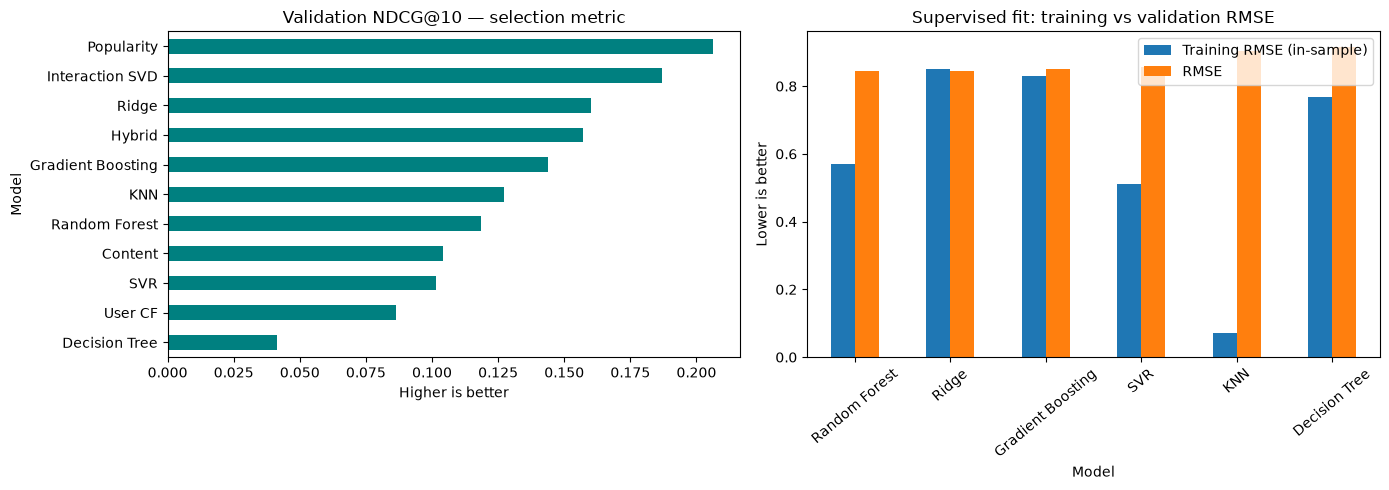

Training RMSE is optimistic: it is measured on rows used to fit the regressor.


In [14]:
selected_model=str(validation_rank.index[0])
selected_supervised=next(name for name in validation_rank.index if name in models)
selection={'selection_metric':'validation NDCG@10', 'tie_breaker':'validation Recall@10',
           'selected_model':selected_model,'selected_supervised':selected_supervised,
           'seed':SEED,'k':K,'relevant_rating':RELEVANT_RATING,
           'hybrid_weights':{'Content':0.60,'User CF':0.35,'Popularity':0.05}}
(OUT/'model_selection.json').write_text(json.dumps(selection,indent=2))
print('Selected overall method:',selected_model)
print('Selected supervised model:',selected_supervised)
fig,axes=plt.subplots(1,2,figsize=(14,5))
validation_rank['NDCG@10'].sort_values().plot.barh(ax=axes[0],color='teal')
axes[0].set(title='Validation NDCG@10 — selection metric',xlabel='Higher is better')
validation_rating[['Training RMSE (in-sample)','RMSE']].plot.bar(ax=axes[1])
axes[1].set(title='Supervised fit: training vs validation RMSE',ylabel='Lower is better')
axes[1].tick_params(axis='x',rotation=40)
show_plot('05_validation_selection')
print('Training RMSE is optimistic: it is measured on rows used to fit the regressor.')

## 15. Refit on Train + Validation and Evaluate on Test

**Refitting all models with the frozen settings.** Test ratings remain excluded from all profiles, aggregates and model fitting. Test rankings describe generalization; they are not used to change the validation-selected model.

In [15]:
development=pd.concat([train,validation]).sort_index()
assert set(development.index).isdisjoint(test.index)
final_models,final_fit_times,final_feature_seconds=fit_supervised(development)
final_state=recommender_state(development)
test_rank,test_users,test_audit=evaluate_ranking(development,test,final_state,final_models,'test')
test_rating,test_predictions=evaluate_ratings(development,test,final_state,final_models,'test')
display(test_rank.round(4))
display(test_rating.round(4))
print('Test evaluation scope:',test_audit)
print('Validation-selected method remains:',selected_model)
print('Highest observed test NDCG (descriptive only):',test_rank.index[0])
assert selection['selected_model']==selected_model
pd.DataFrame({'initial_fit_seconds':pd.Series(fit_times),
              'refit_seconds':pd.Series(final_fit_times)}).to_csv(OUT/'supervised_fit_times.csv')
(OUT/'environment.json').write_text(json.dumps(versions,indent=2))

Ridge: fitted on 6,726 ratings in 0.01s


KNN: fitted on 6,726 ratings in 0.01s


Decision Tree: fitted on 6,726 ratings in 0.19s


SVR: fitted on 6,726 ratings in 2.35s


Random Forest: fitted on 6,726 ratings in 13.07s


Gradient Boosting: fitted on 6,726 ratings in 5.54s


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@10,Users
Model,,,,,,
Interaction SVD,0.0891,0.3920,0.2774,0.5969,0.3932,258
Popularity,0.0899,0.3529,0.2329,0.5426,0.1288,258
Ridge,0.0655,0.2624,0.1745,0.4651,0.2678,258
Gradient Boosting,0.0678,0.2636,0.1690,0.4535,0.2542,258
KNN,0.0593,0.2363,0.1645,0.4186,0.5661,258
Hybrid,0.0609,0.2429,0.1605,0.4147,0.7458,258
Random Forest,0.0574,0.2182,0.1464,0.4031,0.4237,258
User CF,0.0384,0.1861,0.0971,0.3256,0.5932,258
Content,0.0353,0.1419,0.0917,0.2597,0.8271,258


,MAE,RMSE,Training RMSE (in-sample),Rated pairs
Model,,,,
Ridge,0.6342,0.8291,0.8393,1399
Random Forest,0.6359,0.8359,0.5702,1399
Gradient Boosting,0.6418,0.8395,0.8239,1399
SVR,0.6489,0.8622,0.5089,1399
KNN,0.6848,0.8953,0.0749,1399
Decision Tree,0.6813,0.9015,0.7728,1399


Test evaluation scope: {'split': 'test', 'target_users': 349, 'evaluated_users': 258, 'excluded_no_eligible_positive': 91, 'excluded_fewer_than_10_candidates': 0, 'reference_observed_movies': 295, 'target_ratings_outside_reference_catalogue': 11, 'target_positive_ratings_outside_reference_catalogue': 2, 'evaluation_seconds': 30.863}
Validation-selected method remains: Popularity
Highest observed test NDCG (descriptive only): Interaction SVD


109

## 16. Relevant Comparison and Diagnostic Plots

**Plotting top-10 quality, coverage, rating errors and training cost.** Ranking is the primary task; a model with lower rating RMSE is not necessarily the best top-10 recommender. Fit times below cover the six supervised estimators only, excluding shared feature generation and evaluation.

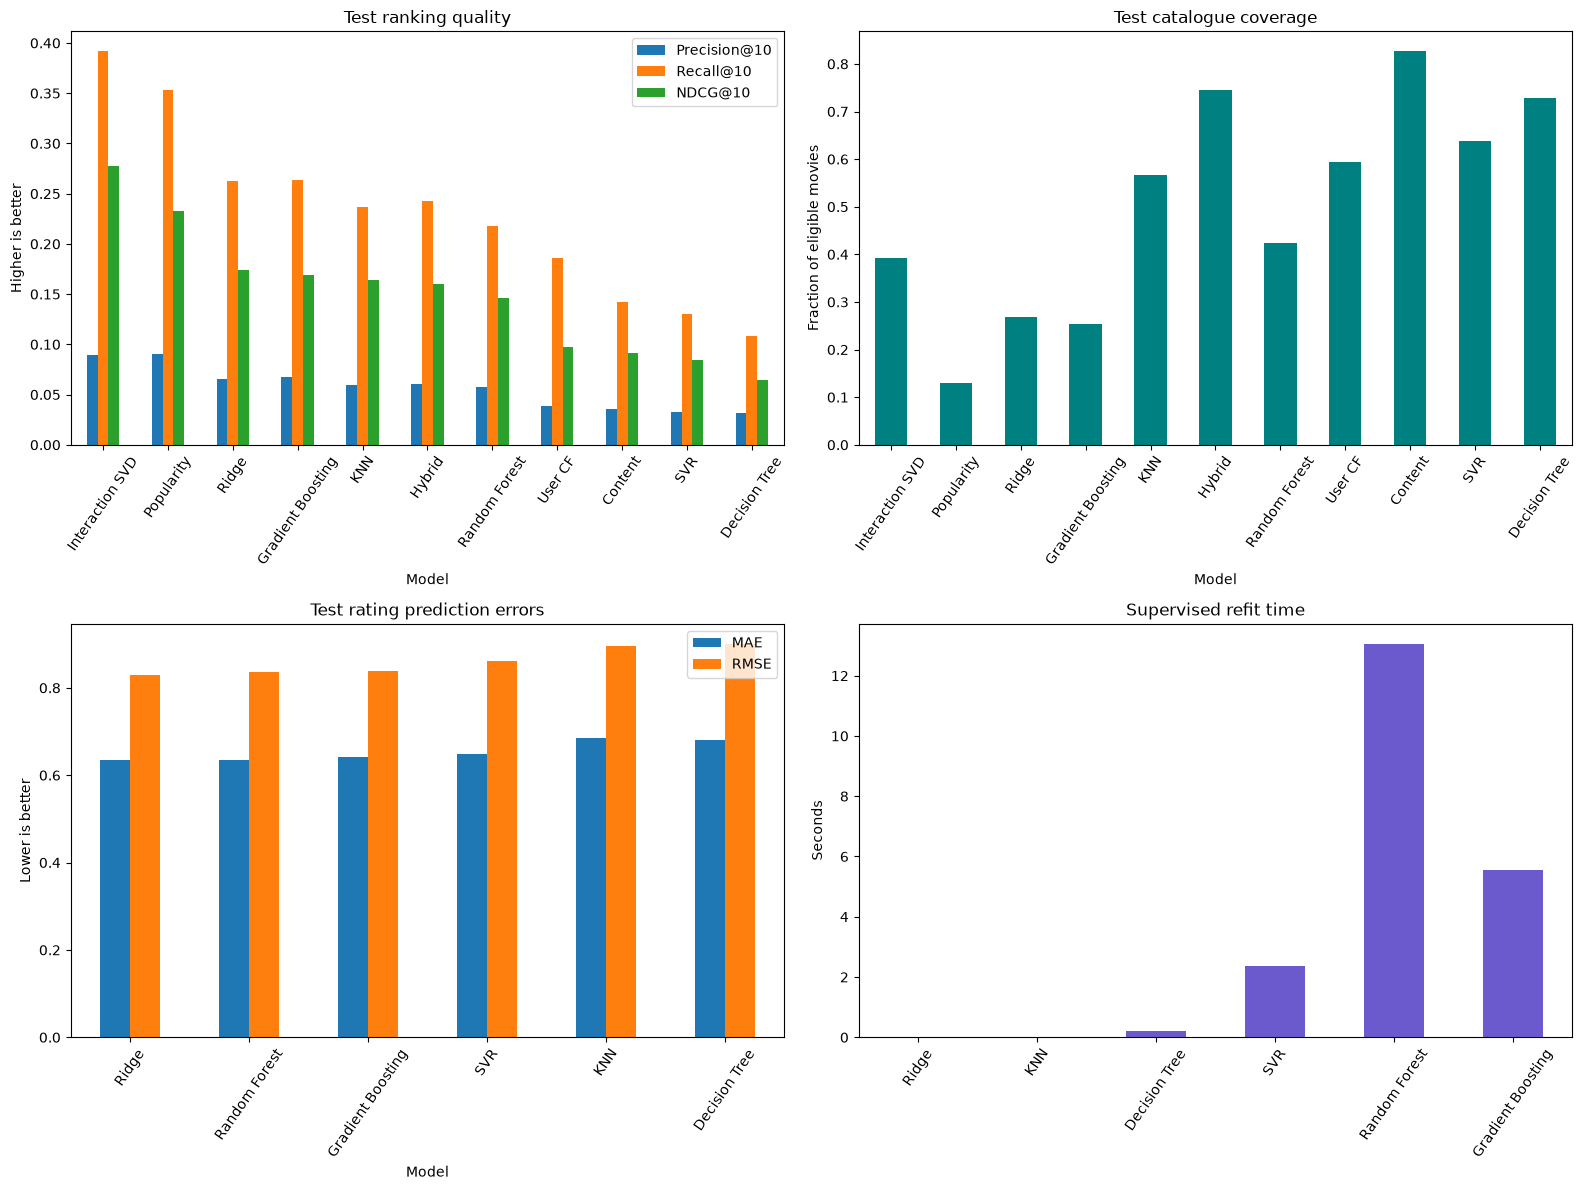

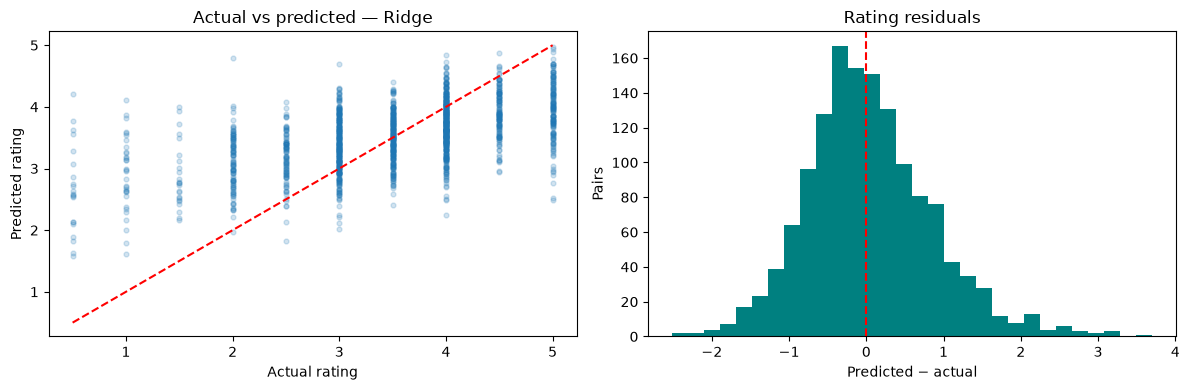

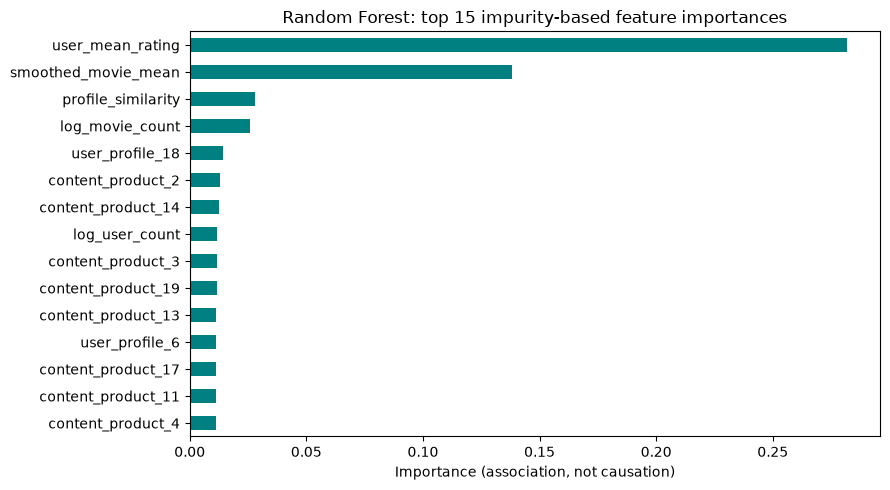

Content dimensions are latent coordinates, not individual words. Impurity importance can be biased.


In [16]:
order=test_rank.index
fig,axes=plt.subplots(2,2,figsize=(16,12))
test_rank.loc[order,['Precision@10','Recall@10','NDCG@10']].plot.bar(ax=axes[0,0])
axes[0,0].set(title='Test ranking quality',ylabel='Higher is better')
test_rank.loc[order,'Coverage@10'].plot.bar(ax=axes[0,1],color='teal')
axes[0,1].set(title='Test catalogue coverage',ylabel='Fraction of eligible movies')
test_rating[['MAE','RMSE']].plot.bar(ax=axes[1,0])
axes[1,0].set(title='Test rating prediction errors',ylabel='Lower is better')
pd.Series(final_fit_times).plot.bar(ax=axes[1,1],color='slateblue')
axes[1,1].set(title='Supervised refit time',ylabel='Seconds')
for ax in axes.ravel():ax.tick_params(axis='x',rotation=55)
show_plot('06_test_comparison')

# Diagnose the validation-selected supervised model, even if a non-regressor wins overall.
pred=test_predictions[selected_supervised]
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(test.rating,pred,alpha=0.2,s=12)
axes[0].plot([0.5,5],[0.5,5],'r--')
axes[0].set(title=f'Actual vs predicted — {selected_supervised}',xlabel='Actual rating',ylabel='Predicted rating')
axes[1].hist(pred-test.rating.to_numpy(),bins=30,color='teal')
axes[1].axvline(0,color='red',linestyle='--')
axes[1].set(title='Rating residuals',xlabel='Predicted − actual',ylabel='Pairs')
show_plot('07_rating_diagnostics')

importance=pd.Series(final_models['Random Forest'].feature_importances_,index=feature_names).sort_values().tail(15)
importance.plot.barh(figsize=(9,5),color='teal')
plt.title('Random Forest: top 15 impurity-based feature importances')
plt.xlabel('Importance (association, not causation)')
show_plot('08_feature_importance')
print('Content dimensions are latent coordinates, not individual words. Impurity importance can be biased.')

## 17. Uncertainty and Result Interpretation

**Bootstrapping users for the selected model's NDCG@10.** The 95% interval reflects variation across evaluated users on this fixed split. It does not capture variation from different training splits, random seeds or title-linkage errors, and is not evidence that one method is significantly better than another.

In [17]:
values=test_users.loc[test_users.Model.eq(selected_model),'NDCG@10'].to_numpy()
rng=np.random.default_rng(SEED)
bootstrap_means=np.array([rng.choice(values,size=len(values),replace=True).mean() for _ in range(1000)])
low,high=np.quantile(bootstrap_means,[0.025,0.975])
selected_result=test_rank.loc[selected_model]
best_rating=str(test_rating.index[0])
conclusion=f"""### Computed conclusion

- Validation selected **{selected_model}** using NDCG@10.
- Its test NDCG@10 is **{selected_result['NDCG@10']:.4f}**; the user-bootstrap 95% interval is **[{low:.4f}, {high:.4f}]**.
- Its test Precision@10 is **{selected_result['Precision@10']:.4f}**, Recall@10 is **{selected_result['Recall@10']:.4f}**, and coverage is **{selected_result['Coverage@10']:.2%}**.
- **{selected_supervised}** was the best supervised ranker on validation. The lowest observed test rating RMSE belongs to **{best_rating}**; this is a different objective.
- Test ranking evaluation includes **{test_audit['evaluated_users']}** users and **{test_audit['reference_observed_movies']}** reference-observed movies. **{test_audit['target_ratings_outside_reference_catalogue']}** test ratings refer to movies outside that candidate catalogue.
- **{test_rank.index[0]}** has the highest observed test NDCG@10 (**{test_rank.iloc[0]['NDCG@10']:.4f}**). This descriptive test result does not replace the validation-selected method.
- There are **{len(matched)}** candidate movie links, covering **{len(matched)/len(movies):.2%}** of the historical movie catalogue. These results cannot be generalized to all JioHotstar users or movies.

The tables report measured results, not a promised accuracy. Model choice is based on validation rather than selecting whichever model happens to win on the test set.
"""
display(Markdown(conclusion))
_ = (OUT/'RESULTS_SUMMARY.md').write_text(conclusion,encoding='utf-8')

### Computed conclusion

- Validation selected **Popularity** using NDCG@10.
- Its test NDCG@10 is **0.2329**; the user-bootstrap 95% interval is **[0.2015, 0.2669]**.
- Its test Precision@10 is **0.0899**, Recall@10 is **0.3529**, and coverage is **12.88%**.
- **Ridge** was the best supervised ranker on validation. The lowest observed test rating RMSE belongs to **Ridge**; this is a different objective.
- Test ranking evaluation includes **258** users and **295** reference-observed movies. **11** test ratings refer to movies outside that candidate catalogue.
- **Interaction SVD** has the highest observed test NDCG@10 (**0.2774**). This descriptive test result does not replace the validation-selected method.
- There are **304** candidate movie links, covering **6.67%** of the historical movie catalogue. These results cannot be generalized to all JioHotstar users or movies.

The tables report measured results, not a promised accuracy. Model choice is based on validation rather than selecting whichever model happens to win on the test set.


## 18. Recommendations for an Existing User

Recommendations use train and validation history, excluding previously rated movies. Held-out test interactions remain unavailable to the recommender. Scores indicate ranking strength; for regressors, they are clipped predicted ratings. Shared genres provide simple recommendation reasons. If popularity is selected, recommendations are nonpersonalized apart from excluding seen movies.


In [18]:
def search_movies(query,limit=15):
    mask=movies.title.str.contains(str(query),case=False,na=False,regex=False)
    return movies.loc[mask,['hotstar_id','title','genre','year']].head(limit)

def recommend_user(user_id,model_name=None,n=10,genre=None):
    model_name=model_name or selected_model
    if model_name not in model_names:raise ValueError('Unknown model. Use one of model_names.')
    user_id=int(user_id)
    if not 0<=user_id<U or final_state['uc'][user_id]==0:
        raise ValueError('Unknown user. Choose an ID from development.userId.unique().')
    if not isinstance(n,int) or n<1:raise ValueError('n must be a positive integer.')
    seen=set(development.loc[development.userId.eq(user_id),'item_idx'].astype(int))
    candidates=np.array([i for i in np.flatnonzero(final_state['ic']>0) if i not in seen],dtype=int)
    if genre:
        candidates=np.array([i for i in candidates if str(genre).lower() in matched.loc[i,'genre'].lower()],dtype=int)
    if not len(candidates):return pd.DataFrame(columns=['title','genre','score','reason'])
    scores=all_scores(user_id,candidates,final_state,final_models)[model_name]
    top=np.argsort(-scores,kind='stable')[:n]
    result=matched.iloc[candidates[top]][['hotstar_id','title','genre','year','running_time']].copy()
    result['score']=scores[top]
    liked_items=development.loc[development.userId.eq(user_id)&development.rating.ge(4),'item_idx']
    liked_genres=set(matched.loc[liked_items,'genre'])
    result['reason']=['Shares a genre with your high-rated history' if g in liked_genres
                      else 'Ranked by '+model_name for g in result.genre]
    result['availability']='Historical listing; current availability unverified'
    assert not set(candidates[top]).intersection(seen)
    return result.reset_index(drop=True)

DEMO_USER=int(development.groupby('userId').size().sort_values(ascending=False).index[0])
print('Example user:',DEMO_USER,'| Selected method:',selected_model)
display(search_movies('Iron Man'))
recommendations=recommend_user(DEMO_USER)
display(recommendations)
recommendations.to_csv(OUT/'example_user_recommendations.csv',index=False)

Example user: 380 | Selected method: Popularity


,hotstar_id,title,genre,year
2663,1260026998,Marvel's Iron Man & Captain America: Heroes United,Animation,2014
2671,1260027013,Marvel's Iron Man & Hulk: Heroes United,Animation,2013
3879,1660000038,Iron Man,Superhero,2008
3880,1660000039,Iron Man 2,Superhero,2010
3881,1660000042,Iron Man 3,Superhero,2013


,hotstar_id,title,genre,year,running_time,score,reason,availability
0,1660010197,Toy Story,Animation,1995,81.0,3.694672,Shares a genre with your high-rated history,Historical listing; current availability unverified
1,1660010169,Wall-E,Animation,2008,98.0,3.547567,Shares a genre with your high-rated history,Historical listing; current availability unverified
2,1260017844,Dead Poets Society,Drama,1989,128.0,3.483853,Ranked by Popularity,Historical listing; current availability unverified
3,1770000746,Little Miss Sunshine,Comedy,2006,102.0,3.326574,Shares a genre with your high-rated history,Historical listing; current availability unverified
4,1260027566,Big,Comedy,1988,104.0,3.274599,Shares a genre with your high-rated history,Historical listing; current availability unverified
5,1260018316,Mary Poppins,Musical,1964,139.0,3.273198,Shares a genre with your high-rated history,Historical listing; current availability unverified
6,1260016855,Ratatouille,Animation,2007,111.0,3.233728,Shares a genre with your high-rated history,Historical listing; current availability unverified
7,1770000948,Avatar,Science Fiction,2009,161.0,3.223220,Shares a genre with your high-rated history,Historical listing; current availability unverified
8,1260018348,Pretty Woman,Romance,1990,119.0,3.222017,Ranked by Popularity,Historical listing; current availability unverified
9,1260105551,Spider-Man 2,Superhero,2004,127.0,3.198003,Shares a genre with your high-rated history,Historical listing; current availability unverified


In [19]:
print(f'Personalized ({selected_supervised}, best supervised model on validation):')
display(recommend_user(DEMO_USER, model_name=selected_supervised))
print('Personalized (Interaction SVD; test comparison, not the selection rule):')
display(recommend_user(DEMO_USER, model_name='Interaction SVD'))


Personalized (Ridge, best supervised model on validation):


,hotstar_id,title,genre,year,running_time,score,reason,availability
0,1660010197,Toy Story,Animation,1995,81.0,4.220491,Shares a genre with your high-rated history,Historical listing; current availability unverified
1,1260017844,Dead Poets Society,Drama,1989,128.0,4.204700,Ranked by Ridge,Historical listing; current availability unverified
2,1660010169,Wall-E,Animation,2008,98.0,4.173767,Shares a genre with your high-rated history,Historical listing; current availability unverified
3,1260105551,Spider-Man 2,Superhero,2004,127.0,4.171116,Shares a genre with your high-rated history,Historical listing; current availability unverified
4,1770019066,"Three Billboards Outside Ebbing, Missouri",Drama,2017,115.0,4.158428,Ranked by Ridge,Historical listing; current availability unverified
5,1770021014,Louis C.K.: Shameless,Standup Comedy,2007,55.0,4.106842,Ranked by Ridge,Historical listing; current availability unverified
6,1260016855,Ratatouille,Animation,2007,111.0,4.072479,Shares a genre with your high-rated history,Historical listing; current availability unverified
7,1770002321,The Martian,Science Fiction,2015,141.0,4.056134,Shares a genre with your high-rated history,Historical listing; current availability unverified
8,1260018316,Mary Poppins,Musical,1964,139.0,4.050682,Shares a genre with your high-rated history,Historical listing; current availability unverified
9,1770000446,X-Men: Days of Future Past,Superhero,2014,131.0,4.037167,Shares a genre with your high-rated history,Historical listing; current availability unverified


Personalized (Interaction SVD; test comparison, not the selection rule):


,hotstar_id,title,genre,year,running_time,score,reason,availability
0,1770000446,X-Men: Days of Future Past,Superhero,2014,131.0,1.008722,Shares a genre with your high-rated history,Historical listing; current availability unverified
1,1260018153,Big Hero 6,Animation,2014,97.0,0.835840,Shares a genre with your high-rated history,Historical listing; current availability unverified
2,1660000045,Who Framed Roger Rabbit,Comedy,1988,99.0,0.644218,Shares a genre with your high-rated history,Historical listing; current availability unverified
3,1260017865,Monsters University,Animation,2013,103.0,0.596089,Shares a genre with your high-rated history,Historical listing; current availability unverified
4,1770000948,Avatar,Science Fiction,2009,161.0,0.499503,Shares a genre with your high-rated history,Historical listing; current availability unverified
5,1660000034,Captain America: The First Avenger,Superhero,2011,124.0,0.496164,Shares a genre with your high-rated history,Historical listing; current availability unverified
6,1260018316,Mary Poppins,Musical,1964,139.0,0.442217,Shares a genre with your high-rated history,Historical listing; current availability unverified
7,1260105551,Spider-Man 2,Superhero,2004,127.0,0.435893,Shares a genre with your high-rated history,Historical listing; current availability unverified
8,1770002321,The Martian,Science Fiction,2015,141.0,0.405082,Shares a genre with your high-rated history,Historical listing; current availability unverified
9,1260018310,The Jungle Book,Adventure,2016,105.0,0.397471,Shares a genre with your high-rated history,Historical listing; current availability unverified


## 19. New-User Content Recommendations

The content-based demonstration averages the TF-IDF profiles of selected favourite movies and ranks similar titles across the full historical catalogue. Favourite movies are excluded; genre and runtime filters are supported. This demonstration does not use test ratings and is separate from the matched-subset evaluation.


In [20]:
full_vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=20000,sublinear_tf=True)
full_text=movies.description.fillna('')+' '+movies.genre+' '+movies.genre
full_T=full_vectorizer.fit_transform(full_text)
full_id_to_row=dict(zip(movies.hotstar_id,movies.index))

def recommend_favourites(favourite_ids,n=10,genre=None,max_minutes=None):
    ids=list(dict.fromkeys(str(x) for x in favourite_ids))
    if not ids:raise ValueError('Choose at least one favourite movie ID using search_movies().')
    unknown=[x for x in ids if x not in full_id_to_row]
    if unknown:raise ValueError('Unknown favourite movie IDs: '+str(unknown))
    if not isinstance(n,int) or n<1:raise ValueError('n must be a positive integer.')
    rows=[full_id_to_row[x] for x in ids]
    profile=normalize(csr_matrix(full_T[rows].mean(axis=0)))
    similarity=np.asarray((full_T@profile.T).toarray()).ravel()
    allowed=~movies.hotstar_id.isin(ids)
    if genre:allowed &= movies.genre.str.contains(str(genre),case=False,regex=False,na=False)
    if max_minutes is not None:allowed &= movies.running_time.le(float(max_minutes))
    candidates=np.flatnonzero(allowed.to_numpy() & (similarity>0))
    top=candidates[np.argsort(-similarity[candidates],kind='stable')[:n]]
    result=movies.iloc[top][['hotstar_id','title','genre','year','running_time']].copy()
    result['content_similarity']=similarity[top]
    result['reason']='Similar description/genre to selected favourites'
    result['availability']='Historical listing; current availability unverified'
    return result.reset_index(drop=True)

# Edit this list after searching for your favourite movies.
FAVOURITE_MOVIE_IDS=['1660000038','1770000948','1660010197']
display(movies.loc[movies.hotstar_id.isin(FAVOURITE_MOVIE_IDS),['hotstar_id','title']])
new_user_recommendations=recommend_favourites(FAVOURITE_MOVIE_IDS)
display(new_user_recommendations)
new_user_recommendations.to_csv(OUT/'example_favourite_recommendations.csv',index=False)

,hotstar_id,title
3879,1660000038,Iron Man
3893,1660010197,Toy Story
3978,1770000948,Avatar


,hotstar_id,title,genre,year,running_time,content_similarity,reason,availability
0,1770000934,Alien Resurrection,Science Fiction,1997,108.0,0.218927,Similar description/genre to selected favourites,Historical listing; current availability unverified
1,1260107902,Bal Ganesh 2,Animation,2009,68.0,0.205289,Similar description/genre to selected favourites,Historical listing; current availability unverified
2,1770000289,The Maze Runner,Science Fiction,2014,108.0,0.195206,Similar description/genre to selected favourites,Historical listing; current availability unverified
3,1770000950,Maze Runner 2: The Scorch Trials,Science Fiction,2015,126.0,0.193480,Similar description/genre to selected favourites,Historical listing; current availability unverified
4,1260016408,John Carter,Science Fiction,2012,132.0,0.191278,Similar description/genre to selected favourites,Historical listing; current availability unverified
5,1260018150,Star Wars: The Force Awakens,Science Fiction,2015,138.0,0.187155,Similar description/genre to selected favourites,Historical listing; current availability unverified
6,1260018308,Inspector Gadget,Science Fiction,1999,74.0,0.186189,Similar description/genre to selected favourites,Historical listing; current availability unverified
7,1260023107,Toy Story Toons: Small Fry,Animation,2011,7.0,0.183678,Similar description/genre to selected favourites,Historical listing; current availability unverified
8,1260015326,Toy Story 4,Animation,2019,100.0,0.182001,Similar description/genre to selected favourites,Historical listing; current availability unverified
9,1260028045,Terminator: Dark Fate,Science Fiction,2019,128.0,0.179378,Similar description/genre to selected favourites,Historical listing; current availability unverified


## 20. Verification Checks

**Checking exclusions, metrics and reproducibility inputs.** These checks catch common mistakes; they do not prove that a model will satisfy every real user.

In [21]:
assert len(final_models)==6
assert isinstance(final_models['Random Forest'],RandomForestRegressor)
assert isinstance(final_models['Gradient Boosting'],GradientBoostingRegressor)
assert test_rank.Users.nunique()==1
assert test_rank[['Precision@10','Recall@10','NDCG@10','HitRate@10','Coverage@10']].ge(0).all().all()
assert test_rank[['Precision@10','Recall@10','NDCG@10','HitRate@10','Coverage@10']].le(1).all().all()
assert recommendations.hotstar_id.is_unique
assert not set(new_user_recommendations.hotstar_id).intersection(FAVOURITE_MOVIE_IDS)
assert recommend_user(DEMO_USER,genre='__nonexistent_genre__').empty
assert recommend_favourites(FAVOURITE_MOVIE_IDS,genre='__nonexistent_genre__').empty
filtered=recommend_favourites(FAVOURITE_MOVIE_IDS,max_minutes=100)
assert filtered.running_time.le(100).all()
# Target-label perturbation must not affect features built from the fixed reference state.
check=test.head(5).copy()
before=pair_features(final_state,check.userId,check.item_idx)
check['rating']=0.5
assert np.array_equal(before,pair_features(final_state,check.userId,check.item_idx))
print('All checks passed. Six trained models, two required ensembles, and 11-method comparison complete.')

All checks passed. Six trained models, two required ensembles, and 11-method comparison complete.


## 21. Conclusion, Limitations and Future Work

The computed conclusion in Section 17 identifies the validation-selected method and reports its held-out results. Six supervised models and two ensemble families are implemented, with five additional recommendation comparisons. The pipeline includes EDA, preprocessing, out-of-fold features, validation-based selection, held-out evaluation, plots and working demonstrations.

**Limitations:**
- The six supervised models did not outperform the validation-selected Popularity baseline on ranking quality. The matched data is sparse (median 6 ratings per user). Random Forest shows a substantial training-to-test RMSE gap (about 0.57 versus 0.84), consistent with overfitting. Gradient Boosting has a much smaller gap; it should not be described as equally overfit. These findings apply to this split and the fixed configurations tested.
- Candidate title/year matching is not manually certified. Incorrect links affect labels and results.
- Ratings cover a small, MovieLens-biased part of the historical catalogue. They are not actual Hotstar viewing histories.
- Offline ranking treats unobserved candidates as nonrelevant for scoring; actual user preference is unknown.
- Random per-user holdout is not a future-time or new-user evaluation. Users without eligible positive targets are excluded and counted in the audit.
- One split, seed and modest fixed configuration per model are tested. No global-optimality or statistical-superiority claim is made.
- Public catalogue text is known in advance. Out-of-fold supervised histories contain fewer ratings than inference histories.
- Full-catalogue content recommendations are a separate unevaluated demo. No current streaming-availability claim is made.

**Future work:** Review identity links manually; obtain a permitted current catalogue and consented interaction data; use temporal evaluation, repeated splits and validation-only hyperparameter search; measure diversity and actual user satisfaction.

## 22. References

1. Hotstar metadata repository: https://github.com/SumitMakariye/Hotstar-Data-Analysis-Using-Python
2. GroupLens MovieLens: https://grouplens.org/datasets/movielens/latest/
3. Harper, F. M. and Konstan, J. A. (2015). *The MovieLens Datasets: History and Context*. https://doi.org/10.1145/2827872
4. Scikit-learn user guide (regression, ensembles, TF-IDF, SVD and metrics): https://scikit-learn.org/stable/user_guide.html
